# Self-consistency (choices): How often the same request changes its answer

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/consistency_choice_cookbook/consistency_choice_cookbook.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/consistency_choice_cookbook/consistency_choice_cookbook.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **Needs a TypeSafe API key.** Set `TYPESAFE_API_KEY` before *Run all*. The
> code downloads this cookbook's saved answers and replays them; to call the
> API instead, set `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/consistency_choice_cookbook).

A pipeline that hands decisions to a model needs the same post to get the same decision
every time. We send one post again and again, unchanged, and count how often a decision
changes: remove or leave up, escalate or auto-resolve, which queue owns it.

That says nothing about whether the decision is right; it comes before that. If the
decision moves when the post hasn't, an appeal can't be reproduced and identical posts get
different treatment. It needs no answer key, only repeats, so every model is measured on
the same footing.

Each of the 8 `Choice` questions comes back as a probability on each of its options, 37
options in all, such as 0.62 that the right action is Strike. A pipeline turns one of those
into a decision with a cutoff: strike when P(Strike) is above 0.6. If the next request
returns 0.55, the same post is no longer struck. Whether a wobble like that changes the
decision depends on where the cutoff sits, and we don't know where yours is, so we count
every cutoff from 0 to 1 equally. Two answers 0.10 apart disagree at 10% of cutoffs.
Averaging that over every pair of repeats gives one number per option: the chance that
asking again changes the decision.

Clear-cut posts are easy for every model, so the test uses borderline ones: 40 versions of
a post, each a different mix of facts a moderation model has to weigh. A pipeline is only
as dependable as its shakiest decision, so each post is scored by its least stable option.

The conditions, each one model plus one setting:

- Claude models `claude-fable-5-1`, `claude-opus-5-5`, `claude-sonnet-5-5` and
  `claude-haiku-5-5`, and GPT models `gpt-6-astra`, `gpt-6.1-sol`, `gpt-6.1-terra` and
  `gpt-6-luna`, each reasoning at high effort.
- `gpt-6.1-terra` and `gpt-6-luna` with reasoning off, at temperature `0` and the API
  default. They are the only models here that take a temperature.
- OpenAI's Decisions API on `gpt-6-luna`.
- Jev 1.14 (`jev-1.14.0`): one `system_one` call over the 8 `Choice` questions.

For Jev, a post's least stable decision changes 4.0% of the time on average, about 1 time
in 25, and never more than 6.7%. Every LLM condition has a post where a decision changes
more than 10% of the time, and depending on the condition, between 2 and 36 of the 40 posts
have a decision that changes more than 1 time in 10. Temperature `0` narrows the gap but
doesn't close it. Luck alone would produce a gap as large as Jev's lead over any LLM
condition less than once in a thousand runs.

## Setup

```bash
pip install anthropic openai matplotlib ipython 'cooksafe>=0.3.0,<0.4.0'
```

then set `TYPESAFE_API_KEY`, `ANTHROPIC_API_KEY`, and `OPENAI_API_KEY`. Numbers below came
from `jev-1.14.0` on 2026-11-02. The LLM answers for the 40 versions were sampled from
2026-11-07 to 2026-11-09, and for the example post on 2026-11-10.

In [ ]:
%pip install -q 'anthropic' 'openai' 'typesafe-sdk>=0.7.0' 'matplotlib' 'ipython' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import copy
import itertools
import json
import os
import random
import textwrap
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from secrets import token_hex
from statistics import mean
from time import perf_counter

import anthropic
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap
from matplotlib.ticker import PercentFormatter
from openai import OpenAI
from typesafe_sdk import Choice, TypeSafeClient

matplotlib.use("Agg")  # headless render

LLM_MODELS = {  # every one reasons at high effort
    "claude-fable-5-1": "Claude Fable 5.1",
    "claude-opus-5-5": "Claude Opus 5.5",
    "claude-sonnet-5-5": "Claude Sonnet 5.5",
    "claude-haiku-5-5": "Claude Haiku 5.5",
    "gpt-6-astra": "GPT-6 Astra",
    "gpt-6.1-sol": "GPT-6.1 Sol",
    "gpt-6.1-terra": "GPT-6.1 Terra",
    "gpt-6-luna": "GPT-6 Luna",
}
TEMPERATURE_MODELS = ["gpt-6.1-terra", "gpt-6-luna"]  # also reasoning off: temperature 0 + default
DECISIONS_MODEL = "gpt-6-luna"  # through OpenAI's Decisions API
TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
NUM_SAMPLES = 15  # repeated post+rubric calls per condition
NUM_POSTS = 40  # versions of the post, drawn from the combinations of the borderline facts

LLM_PRICES = {  # $ per 1M tokens (input, output), list prices as of 2026-11
    "claude-fable-5-1": (10.00, 50.00),
    "claude-opus-5-5": (4.00, 20.00),
    "claude-sonnet-5-5": (2.00, 10.00),
    "claude-haiku-5-5": (0.10, 0.50),
    "gpt-6-astra": (10.00, 50.00),
    "gpt-6.1-sol": (2.00, 10.00),
    "gpt-6.1-terra": (1.00, 5.00),
    "gpt-6-luna": (0.10, 0.50),
}
DECISIONS_PRICE = (0.10, 0.00)  # $ per 1M tokens (input, output); output tokens are free
TYPESAFE_PRICE = (0.042, 0.00)  # $ per 1M tokens (input, output), as of 2026-08

anthropic_client = anthropic.Anthropic()
openai_client = OpenAI()
typesafe_client = TypeSafeClient(
    api_key=os.environ["TYPESAFE_API_KEY"],
    base_url="https://api.typesafe.ai",
    timeout=30.0,
)

## The state: a borderline user post, as JSON

The post below is built to sit on the fence. The language is heated and insulting, aimed
partly at one person and partly at the argument and the community. It includes an
off-platform invite (a link pulling people to another site) and wording that sounds like a
threat without stating one. The account has one prior strike, and four users have reported
the post.

This is the example post.

The LLMs get `json.dumps(post)` in the prompt. Jev gets the structure directly.

In [ ]:
POST = {
    "post_id": "P-88213",
    "author": {
        "user_id": "user_4471",
        "account_age_days": 38,
        "prior_strikes": 1,
        "followers": 210,
    },
    "context": {
        "surface": "public reply",
        "in_reply_to": "another user defending a game patch",
        "community": "example-game-debates",
    },
    "content": {
        "text": (
            "Are you seriously this dense? Anyone who defends that patch is a complete clown and "
            "should be embarrassed to even post here. People like you are what's ruining this "
            "community and honestly you need to be dealt with. Come say it to my face, invite's "
            "right here. Keep it up and I'll end your whole channel."
        ),
        "has_link": True,
        "link_domain": "chat.example",
        "language": "en",
    },
    "reports": {"user_reports": 4, "report_reasons": ["harassment", "spam", "threat"]},
}

## The rubric: 8 `Choice` questions

Each question has a `key`, a line of instructions, and a fixed set of options. The
options within a question are mutually exclusive (exactly one applies), and each carries
a short description. Jev returns a picked `choice` plus a `probabilities`
distribution over the options. The LLMs are asked to use the same options, which makes
the LLM and Jev answers comparable.

In [ ]:
QUESTIONS = {
    "category": (
        "What is the single most applicable content-policy category for this post?",
        {
            "None": "No policy violation of any kind.",
            "Harass": "Insults or demeans a person, with no threat of harm and no protected-class attack.",
            "Hate": "Attacks a person or group over a protected characteristic (race, religion, gender, ...).",
            "Violence": "Makes a credible threat of harm or incites violence against someone.",
            "Spam": "Unsolicited promotion or link spam, with no personal attack.",
            "Sexual": "Sexual or adult content.",
        },
    ),
    "primary_risk": (
        "What is the primary moderation risk that should drive triage for this post?",
        {
            "Harassment": "Personal attack or targeted abuse is the main risk.",
            "Violence": "A threat of harm or intimidation is the main risk.",
            "LinkAbuse": "External-link or off-platform coordination risk is the main risk.",
            "AccountHistory": "Prior account history or repeat behavior is the main risk.",
            "LowRisk": "No meaningful moderation risk is present.",
        },
    ),
    "target": (
        "Who or what is the content primarily directed at?",
        {
            "None": "Not directed at anyone in particular.",
            "Person": "Directed at one specific individual.",
            "Group": "Directed at a protected group or class.",
            "Platform": "Directed at the community or platform itself, not a person.",
        },
    ),
    "action": (
        "What enforcement action should be taken on this post?",
        {
            "Allow": "Leave the post up with no action.",
            "Warn": "Leave the post up but attach a warning label.",
            "Remove": "Remove the post, but do not penalize the account.",
            "Strike": "Remove the post and add a strike to the account.",
            "Escalate": "Take no automated action; hold for a human decision.",
        },
    ),
    "queue": (
        "Which single moderation queue should own this post?",
        {
            "Auto": "Auto-resolve; no human queue needed.",
            "General": "General moderation queue.",
            "Threat": "Threat / violence response queue.",
            "Spam": "Spam and platform-abuse queue.",
            "TSLead": "Trust-and-safety lead / senior queue.",
        },
    ),
    "link_handling": (
        "How should any external link or off-platform invite in the post be handled?",
        {
            "Allow": "Leave the link in place.",
            "RmLink": "Strip or disable the link but keep the post.",
            "Brigade": "Treat the link as coordinated brigading and action it as abuse.",
            "Escalate": "Send the link to a specialist to assess before acting.",
        },
    ),
    "review_path": (
        "Who should make the final call on this post?",
        {
            "Auto": "Automated action; no human review.",
            "Human": "A frontline human moderator makes the call.",
            "Senior": "A senior or specialist reviewer is required.",
            "Legal": "Route to legal or law-enforcement escalation.",
        },
    ),
    "severity": (
        "What is the overall severity of this post?",
        {
            "None": "No violation.",
            "Low": "Rude or dismissive, but essentially harmless.",
            "Medium": "Personal harassment with no clearly credible threat.",
            "High": "Harassment together with a threat that could be read as credible.",
        },
    ),
}
QUESTIONS_JSON = json.dumps(QUESTIONS)

## How we ask

Each LLM call is one prompt holding `json.dumps(post)`, all 8 questions, and every allowed
option. The model answers through structured output: a JSON schema that requires, for each
question, a probability on every one of its options. Calls route to Anthropic or OpenAI by
model name. Reasoning runs at `high` effort; with reasoning off, `gpt-6.1-terra` and
`gpt-6-luna` take a `temperature`, `0` or the API default.

The Decisions API call sends the same post as JSON and asks each `Choice` question as a
Decisions `choice` question, which comes back with a probability on each option.

The TypeSafe call is one `system_one` request over the same post and the same 8
`Choice` questions, returning one distribution per question.

Every query also gets a fresh `uid`, a throwaway unique value that changes each run while
leaving the post and rubric unchanged. It appears in the LLM prompt and as an extra field
in the TypeSafe and Decisions API states. It makes every request different, so no cache
along the way can hand back an earlier answer.

For every call we also record its cost and round-trip time.

In [ ]:
def argmax_label(values: list, labels: list[str]) -> str | None:
    """The label with the most probability mass, or ``None`` if any value is missing or
    non-numeric -- a partially parsed distribution never yields a confident-looking pick."""
    numeric = [_numeric_value(value) for value in values]
    if any(value is None for value in numeric):
        return None
    return labels[int(np.argmax(numeric))]


def _numeric_value(value: object) -> float | None:
    """A finite numeric value, or ``None`` if the model emitted something unusable."""
    try:
        numeric = float(value)
    except (TypeError, ValueError):
        return None
    return numeric if np.isfinite(numeric) else None


def parse_distribution(raw: object, labels: list[str]) -> list[float]:
    """Map a model's per-question reply to per-label probabilities, in label order.

    Anything that doesn't match a known label or isn't a finite number is left NaN -- we report
    the gap rather than massaging the reply (e.g. stripping an echoed description) to make it
    fit."""
    if not isinstance(raw, dict):
        return [float("nan")] * len(labels)
    return [
        value if (value := _numeric_value(raw.get(label))) is not None else float("nan")
        for label in labels
    ]


def rubric_prompt(sample_index: int, post: dict, questions: dict) -> str:
    """The post + all questions (with their label sets) in one prompt, asking for a
    probability distribution per question. ``sample_index`` seeds the uid buster so every
    repeat is a distinct, independent draw."""
    lines = []
    for key, (instructions, choices) in questions.items():
        labels = "\n".join(f"     {label}: {desc}" for label, desc in choices.items())
        lines.append(f"- {key}: {instructions}\n   labels:\n{labels}")
    return (
        f"uid: {sample_index}:{token_hex(4)}\n\n"
        f"Document (a reported user post):\n{json.dumps(post, indent=2)}\n\nQuestions:\n"
        + "\n".join(lines)
        + "\n\nEach question's labels are mutually exclusive: exactly one applies. If a post could "
        "arguably fit more than one, pick the single most severe / most specific label per the "
        "label descriptions."
        + "\n\nFor each question, give a probability distribution over that question's labels "
        "(values 0.00-1.00 that sum to 1).\nRespond with ONLY a JSON object mapping each "
        "question's key to an object mapping that question's bare labels (the label only, "
        "not its description) to probabilities, with one entry per question."
    )


def _cost(prices: tuple[float, float], input_tokens: int, output_tokens: int) -> float:
    return input_tokens / 1e6 * prices[0] + output_tokens / 1e6 * prices[1]


def _answer_schema(questions: dict) -> dict:
    """Structured output: for each question, exactly one number per option."""
    properties = {
        key: {
            "type": "object",
            "properties": {label: {"type": "number"} for label in choices},
            "required": list(choices),
            "additionalProperties": False,
        }
        for key, (_instructions, choices) in questions.items()
    }
    return {
        "type": "object",
        "properties": properties,
        "required": list(properties),
        "additionalProperties": False,
    }


def _call_llm(model: str, prompt: str, schema: dict, reasoning: str,
              temperature: float | None):
    """One LLM call -> (text, cost_usd, latency_s), routed by model name. ``reasoning`` is the
    effort; ``"none"`` turns reasoning off, which only the GPT models allow."""
    started = perf_counter()
    if model.startswith("claude"):
        with anthropic_client.messages.stream(
            model=model,
            max_tokens=32000,
            messages=[{"role": "user", "content": prompt}],
            thinking={"type": "adaptive"},
            output_config={"format": {"type": "json_schema", "schema": schema},
                           "effort": reasoning},
        ) as stream:
            response = stream.get_final_message()
        text = next((b.text for b in response.content if b.type == "text"), "")
        usage = (response.usage.input_tokens, response.usage.output_tokens)
    else:
        kwargs = {
            "model": model,
            "messages": [{"role": "user", "content": prompt}],
            "response_format": {
                "type": "json_schema",
                "json_schema": {"name": "rubric", "schema": schema, "strict": True},
            },
            "reasoning_effort": reasoning,
        }
        if temperature is not None:
            kwargs["temperature"] = temperature
        response = openai_client.chat.completions.create(**kwargs)
        text = response.choices[0].message.content or ""
        usage = (response.usage.prompt_tokens, response.usage.completion_tokens)
    return text, _cost(LLM_PRICES[model], *usage), perf_counter() - started


def _query_llm(model, reasoning, temperature, sample_index, post_json, questions_json):
    """One LLM rubric query -> (label distributions keyed by question key, cost_usd,
    latency_s); NaNs where the reply doesn't parse."""
    questions = json.loads(questions_json)
    prompt = rubric_prompt(sample_index, json.loads(post_json), questions)
    text, cost, latency = _call_llm(model, prompt, _answer_schema(questions), reasoning,
                                    temperature)
    try:
        raw = json.loads(text)
    except (ValueError, json.JSONDecodeError):
        raw = {}
    if not isinstance(raw, dict):
        raw = {}
    distributions = {
        key: parse_distribution(raw.get(key), list(choices))
        for key, (_instructions, choices) in questions.items()
    }
    return distributions, cost, latency


def _query_decisions(sample_index, post_json, questions_json, decisions_model):
    """One Decisions API call -> (label distributions keyed by question key, cost_usd,
    latency_s)."""
    questions = json.loads(questions_json)
    state = {"uid": f"{sample_index}:{token_hex(4)}", "post": json.loads(post_json)}
    started = perf_counter()
    response = openai_client.post(
        "/decisions",
        cast_to=object,
        body={
            "model": decisions_model,
            "input": [{"role": "user", "content": [{"type": "input_json", "data": state}]}],
            "questions": [
                {
                    "type": "choice",
                    "name": key,
                    "instructions": instructions,
                    "choices": [
                        {"value": label, "description": description}
                        for label, description in choices.items()
                    ],
                }
                for key, (instructions, choices) in questions.items()
            ],
        },
    )
    latency = perf_counter() - started
    answers = {answer.get("name"): answer for answer in response.get("answers") or []}
    distributions = {}
    for key, (_instructions, choices) in questions.items():
        probabilities = {
            str(item.get("value")): item.get("probability")
            for item in (answers.get(key) or {}).get("probabilities") or []
        }
        distributions[key] = parse_distribution(probabilities, list(choices))
    usage = response.get("usage") or {}
    cost = _cost(DECISIONS_PRICE, usage.get("input_tokens") or 0, usage.get("output_tokens") or 0)
    return distributions, cost, latency


def _query_typesafe(sample_index, post_json, questions_json, model):
    """One TypeSafe call -> (label distributions keyed by question key, input tokens,
    output tokens, latency_s)."""
    questions = json.loads(questions_json)
    started = perf_counter()
    response = typesafe_client.system_one(
        model=model,
        state={"uid": f"{sample_index}:{token_hex(4)}", "post": json.loads(post_json)},
        questions={
            key: Choice(instructions=instructions, criteria=choices)
            for key, (instructions, choices) in questions.items()
        },
    )
    distributions = {}
    for key, (_instructions, choices) in questions.items():
        probabilities = dict(response.answers[key].probabilities)
        distributions[key] = [probabilities.get(label, float("nan")) for label in choices]
    return (
        distributions,
        response.usage.input_tokens,
        response.usage.output_tokens,
        perf_counter() - started,
    )


# Every sample is saved in the cache file, so a second run makes no requests. The post
# and the questions are part of every key, so editing either asks again; ``sample_index`` is
# part of the key too, so each of the NUM_SAMPLES repeats is its own independent draw.

EXAMPLES_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/consistency_choice_cookbook"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        urllib.request.urlretrieve(f"{EXAMPLES_URL}/{name}", path)
    return path


CACHE = Path("consistency_choice_cookbook_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)


@json_cache
def ask_llm(model: str, reasoning: str, temperature: float | None, sample_index: int,
            post_json: str, questions_json: str):
    """The example post's LLM answers, with cost and latency."""
    return _query_llm(model, reasoning, temperature, sample_index, post_json, questions_json)


@json_cache
def ask_decisions(sample_index: int, post_json: str, questions_json: str, decisions_model: str):
    """The example post's Decisions API answers, with cost and latency."""
    return _query_decisions(sample_index, post_json, questions_json, decisions_model)


@json_cache
def ask_typesafe(sample_index: int, post_json: str, questions_json: str, model: str):
    """The example post's Jev answers, with token usage and latency."""
    return _query_typesafe(sample_index, post_json, questions_json, model)


@json_cache
def sweep_llm(model: str, reasoning: str, temperature: float | None, sample_index: int,
              post_json: str, questions_json: str):
    """One LLM answer set for one version of the post."""
    return _query_llm(model, reasoning, temperature, sample_index, post_json, questions_json)[0]


@json_cache
def sweep_decisions(sample_index: int, post_json: str, questions_json: str, decisions_model: str):
    """One Decisions API answer set for one version of the post."""
    return _query_decisions(sample_index, post_json, questions_json, decisions_model)[0]


@json_cache
def sweep_typesafe(sample_index: int, post_json: str, questions_json: str, model: str):
    """One Jev answer set for one version of the post."""
    return _query_typesafe(sample_index, post_json, questions_json, model)[0]

## The conditions

| Model group | Model | Reasoning (high) | Temperature 0 | Default temperature |
| --- | --- | :---: | :---: | :---: |
| Claude | `claude-fable-5-1` | ✓ | — | — |
| Claude | `claude-opus-5-5` | ✓ | — | — |
| Claude | `claude-sonnet-5-5` | ✓ | — | — |
| Claude | `claude-haiku-5-5` | ✓ | — | — |
| GPT | `gpt-6-astra` | ✓ | — | — |
| GPT | `gpt-6.1-sol` | ✓ | — | — |
| GPT | `gpt-6.1-terra` | ✓ | ✓ | ✓ |
| GPT | `gpt-6-luna` | ✓ | ✓ | ✓ |
| Decisions API | `gpt-6-luna` | — | — | ✓ |
| System One | `jev-1.14.0` | — | — | ✓ |

- A check mark is one condition, run 15 times per post. A dash is a combination that was
  not tested.
- The temperature columns have reasoning off. The Claude models take no temperature, and
  neither do GPT models while they reason.
- For the default column we send no temperature argument.
- Temperature `0` is commonly suggested for repeatability, so we compare it with the API
  default where a model takes one.

In [ ]:
DECISIONS_LABEL = "OpenAI Decisions (GPT-6 Luna)"
CONDITIONS = [
    {"label": f"{name} (reasoning)", "model": model, "reasoning": "high", "temp": None}
    for model, name in LLM_MODELS.items()
] + [
    {"label": f"{LLM_MODELS[model]} ({setting})", "model": model, "reasoning": "none",
     "temp": temp}
    for model in TEMPERATURE_MODELS
    for temp, setting in ((0, "temperature 0"), (None, "default temperature"))
] + [{"label": DECISIONS_LABEL, "model": None, "reasoning": None, "temp": None}]
LABELS = [condition["label"] for condition in CONDITIONS]
TYPESAFE_LABEL = "Jev 1.14"
ALL_LABELS = [*LABELS, TYPESAFE_LABEL]
# Rows of the example plot, the same on both self-consistency pages: Jev and a few of the
# conditions, since every condition would make it too tall to read.
PLOT_ORDER = [
    TYPESAFE_LABEL,
    "Claude Opus 5.5 (reasoning)",
    "Claude Haiku 5.5 (reasoning)",
    "GPT-6.1 Sol (reasoning)",
    "GPT-6 Luna (temperature 0)",
    "GPT-6 Luna (default temperature)",
    DECISIONS_LABEL,
]
STRIP_ORDER = [TYPESAFE_LABEL, *LABELS]  # rows of the final plot: every condition


def ask(llm_fn, decisions_fn, condition: dict, sample_index: int, post_json: str):
    """One cached call for one condition: the LLM function, or the Decisions API one."""
    if condition["model"] is None:
        return decisions_fn(sample_index, post_json, QUESTIONS_JSON,
                            decisions_model=DECISIONS_MODEL)
    return llm_fn(condition["model"], condition["reasoning"], condition["temp"], sample_index,
                  post_json, QUESTIONS_JSON)
POST_JSON = json.dumps(POST)

runs: dict[str, list] = {}  # label -> NUM_SAMPLES samples of {question key: distribution}
stats: dict[str, list] = {}  # label -> NUM_SAMPLES (cost_usd, latency_s) pairs
with ThreadPoolExecutor(max_workers=16) as pool:
    futures = {
        condition["label"]: [
            pool.submit(ask, ask_llm, ask_decisions, condition, sample_index, POST_JSON)
            for sample_index in range(NUM_SAMPLES)
        ]
        for condition in CONDITIONS
    }
    for label, sample_futures in futures.items():
        results = [future.result() for future in sample_futures]
        runs[label] = [result[0] for result in results]
        stats[label] = [(result[1], result[2]) for result in results]

# Jev samples are drawn sequentially after the LLM calls, so each latency is a clean
# round trip rather than one measured under the 16-way LLM thread contention.
typesafe_usage_results = [
    ask_typesafe(sample_index, POST_JSON, QUESTIONS_JSON, model=TYPESAFE_MODEL)
    for sample_index in range(NUM_SAMPLES)
]
# Apply pricing after cache retrieval so price changes do not require new samples.
runs[TYPESAFE_LABEL] = [result[0] for result in typesafe_usage_results]
stats[TYPESAFE_LABEL] = [
    (_cost(TYPESAFE_PRICE, input_tokens, output_tokens), latency)
    for _distributions, input_tokens, output_tokens, latency in typesafe_usage_results
]

### Cost + speed (per rubric query)

Costs use the per-token prices in Setup: list prices as of 2026-11 for the LLMs and the
Decisions API, and TypeSafe's rate as of 2026-08.

One row is one full 8-question rubric call on the example post. `time/call` and
`cost/call` average the 15 calls, and the `vs Jev 1.14` columns divide by the Jev 1.14
figures.

In [ ]:
typesafe_cost = mean([cost for cost, _latency in stats[TYPESAFE_LABEL]])
typesafe_latency = mean([latency for _cost, latency in stats[TYPESAFE_LABEL]])
name_w = max(len(name) for name in ALL_LABELS) + 2  # fit the longest condition label
# Stack comparison headers so the relative speed and cost columns can stay narrow.
print(
    f"{'':<{name_w + 31}}{'speed vs':>11}{'cost vs':>11}\n"
    f"{'condition':<{name_w}}{'calls':>7}{'time/call':>11}{'cost/call':>13}"
    f"{TYPESAFE_LABEL:>11}{TYPESAFE_LABEL:>11}"
)
for name in ALL_LABELS:
    costs, latencies = zip(*stats[name])
    cost = mean(costs)
    latency = mean(latencies)
    print(
        f"{name:<{name_w}}{len(costs):>7}{latency * 1000:>9.0f}ms"
        f"{'$' + format(cost, '.6f'):>13}"
        f"{format(latency / typesafe_latency, '.1f') + 'x':>11}"
        f"{format(cost / typesafe_cost, '.1f') + 'x':>11}"
    )

                                                                       speed vs    cost vs
condition                              calls  time/call    cost/call   Jev 1.14   Jev 1.14
Claude Fable 5.1 (reasoning)              15    12793ms    $0.077985     124.5x    1189.0x
Claude Opus 5.5 (reasoning)               15     7841ms    $0.027427      76.3x     418.2x
Claude Sonnet 5.5 (reasoning)             15     3627ms    $0.009907      35.3x     151.0x
Claude Haiku 5.5 (reasoning)              15     6110ms    $0.001019      59.5x      15.5x
GPT-6 Astra (reasoning)                   15    18171ms    $0.055399     176.9x     844.6x
GPT-6.1 Sol (reasoning)                   15    12335ms    $0.010125     120.1x     154.4x
GPT-6.1 Terra (reasoning)                 15    11829ms    $0.005616     115.2x      85.6x
GPT-6 Luna (reasoning)                    15    14467ms    $0.000685     140.8x      10.4x
GPT-6.1 Terra (temperature 0)             15     4274ms    $0.002694      41.6x      41.1x

In this run Jev has a mean round-trip latency of 103ms. The LLM conditions range from 2.8
to 18.2 seconds per call under the concurrency settings above, and the Decisions API takes
0.3 seconds.

## Plot: every sample's top option on the example post

How to read it:

- Outer row group: the question.
- Inner row: the condition.
- Column: one full rubric call.
- Cell text: the top option plus its probability.
- Cell color: the option's position within that question, so the same color all the way
  across a row means the same top option every time.
- Hatched `n/a`: the reply did not parse into usable options (a parse failure).

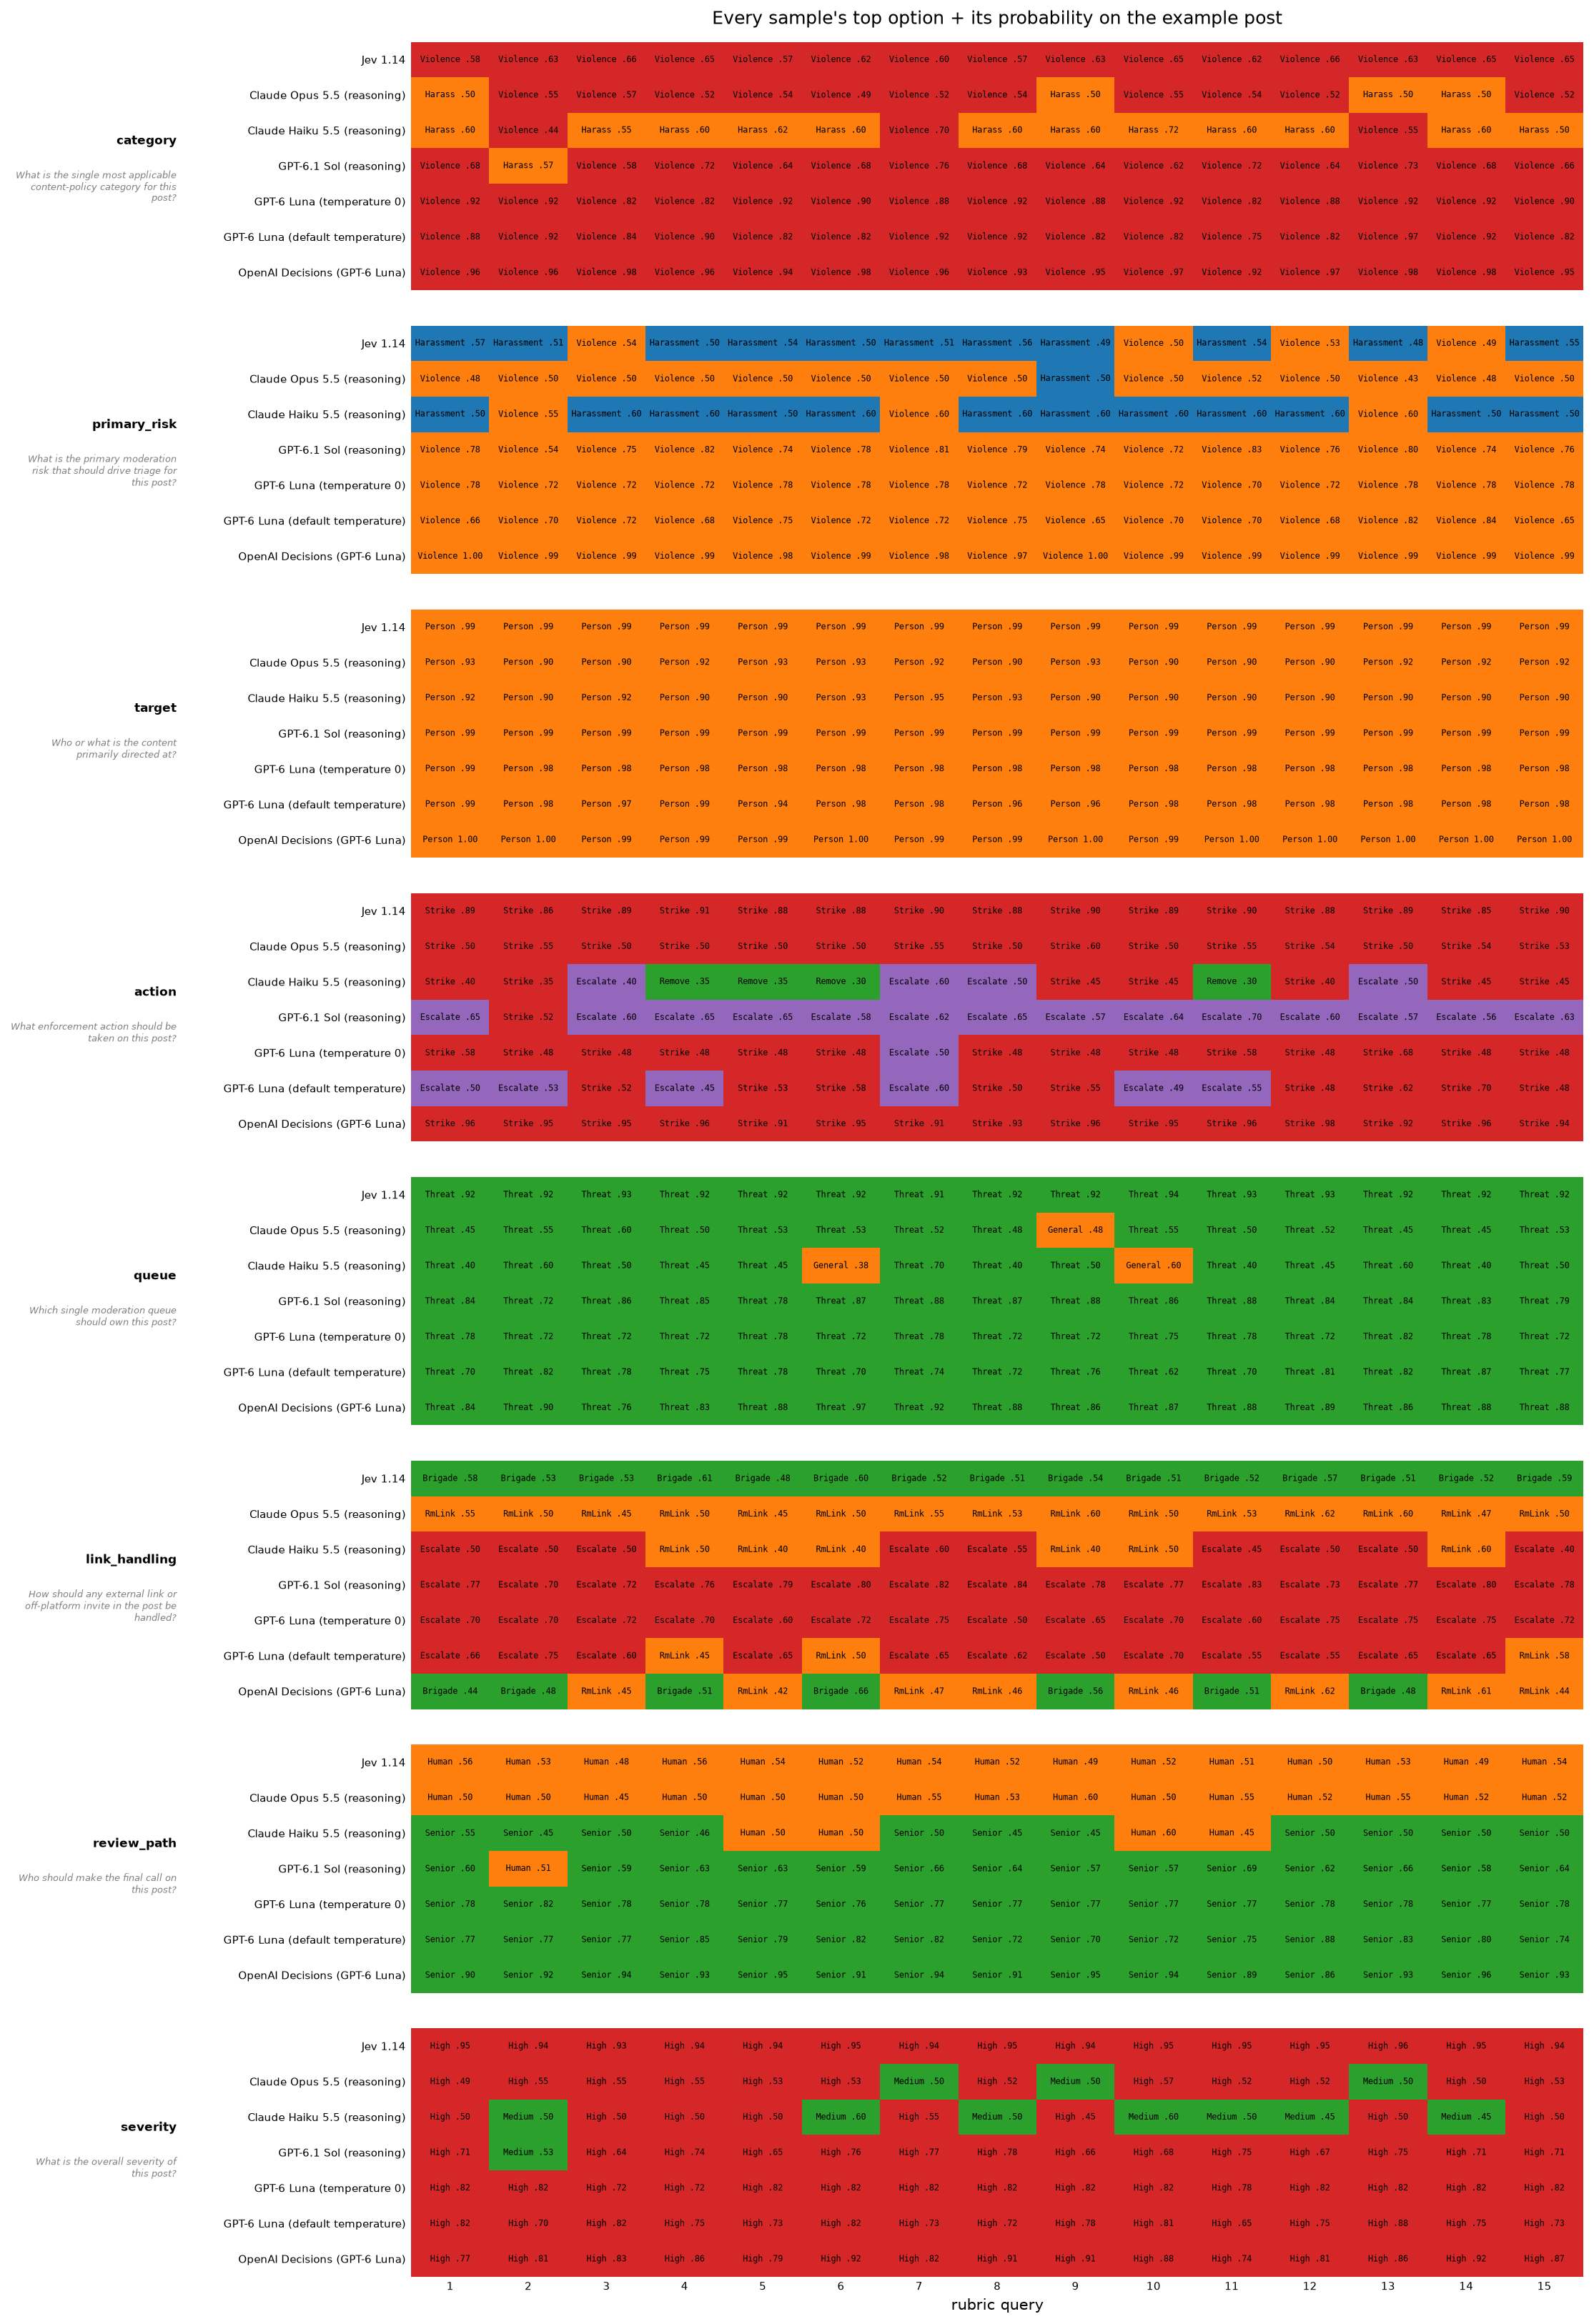

In [ ]:
GAP = 1  # blank spacer row(s) between question blocks
rows_per_block = len(PLOT_ORDER)  # rows per question block


def top_label_annotation(values: list, labels: list[str]) -> str:
    """The top label and its probability, for a heatmap cell."""
    label = argmax_label(values, labels)
    if label is None:
        return ""
    probability_text = f"{max(float(value) for value in values):.2f}".removeprefix("0")
    return f"{label} {probability_text}"


row_index_values, row_text, row_labels, blocks = [], [], [], []
for question_index, (question_key, (question_text, choices)) in enumerate(
    QUESTIONS.items()
):
    labels = list(choices)
    if question_index:  # blank spacer rows (NaN -> rendered white) separate the blocks
        row_index_values.extend([np.nan] * NUM_SAMPLES for _ in range(GAP))
        row_text.extend([[""] * NUM_SAMPLES for _ in range(GAP)])
        row_labels.extend([""] * GAP)
    blocks.append((len(row_index_values), question_key, question_text))
    for label in PLOT_ORDER:
        values_by_sample = [runs[label][sample][question_key] for sample in range(NUM_SAMPLES)]
        picks = [argmax_label(values, labels) for values in values_by_sample]
        row_index_values.append(
            [labels.index(pick) if pick in labels else np.nan for pick in picks]
        )
        row_text.append(
            [top_label_annotation(values, labels) for values in values_by_sample]
        )
        row_labels.append(label)

heatmap_matrix = np.array(row_index_values, dtype=float)
cmap = ListedColormap(plt.get_cmap("tab10").colors)
cmap.set_bad(
    "white"
)  # NaN cells (spacer rows AND unparseable replies) render white here...

fig, ax = plt.subplots(figsize=(15, 0.33 * len(row_index_values) + 1))
ax.imshow(heatmap_matrix, cmap=cmap, vmin=0, vmax=9, aspect="auto")
for row in range(heatmap_matrix.shape[0]):
    is_spacer_row = row_labels[row] == ""  # blank separator between question blocks
    for col in range(heatmap_matrix.shape[1]):
        label_text = row_text[row][col]
        if label_text:
            ax.text(
                col,
                row,
                label_text,
                ha="center",
                va="center",
                fontsize=5.7,
                family="monospace",
                color="black",
            )
        elif (
            not is_spacer_row
        ):  # ...but an unparseable reply gets a hatched "n/a", not blank white
            ax.add_patch(
                plt.Rectangle(
                    (col - 0.5, row - 0.5),
                    1,
                    1,
                    facecolor="#e8e8e8",
                    edgecolor="#b0b0b0",
                    hatch="////",
                    linewidth=0,
                )
            )
            ax.text(
                col,
                row,
                "n/a",
                ha="center",
                va="center",
                fontsize=5,
                family="monospace",
                color="#b30000",
            )

ax.set_xticks(range(NUM_SAMPLES))
ax.set_xticklabels(range(1, NUM_SAMPLES + 1), fontsize=7)
ax.set_xlabel("rubric query")
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=7)
ax.tick_params(length=0)
for edge in ("top", "right", "left", "bottom"):
    ax.spines[edge].set_visible(False)

# outer level of the multi-index: the question key, printed once per block and centered, with the
# question text wrapped right under it
y_axis_transform = ax.get_yaxis_transform()
for start, question_key, question_text in blocks:
    center = start + (rows_per_block - 1) / 2
    ax.text(
        -0.2,
        center - 0.7,
        question_key,
        transform=y_axis_transform,
        ha="right",
        va="center",
        fontsize=8,
        fontweight="bold",
    )
    ax.text(
        -0.2,
        center + 0.1,
        textwrap.fill(question_text, 34),
        transform=y_axis_transform,
        ha="right",
        va="top",
        fontsize=6,
        style="italic",
        color="gray",
    )

ax.set_title(
    "Every sample's top option + its probability on the example post",
    pad=12,
)
fig.tight_layout()
display(fig)

`target` reads Person on every repeat of every condition. Jev changes its top option on one
question, `primary_risk`: Harassment 11 times and Violence 4 times, with both near 0.5.
Claude Haiku 5.5 changes its top option on 7 of the 8 questions, and splits `action` three
ways between Strike, Escalate and Remove. Claude Opus 5.5 and GPT-6.1 Sol each change it on
4 questions. GPT-6 Luna changes `action` once at temperature `0`; at its default
temperature it splits `action` and `link_handling`. The Decisions API splits
`link_handling` almost evenly between Brigade and RmLink.

A change of top option shows only the moves that reorder two options. A probability can
move a long way without reordering anything, and a cutoff set anywhere along that move
changes the decision.

## 40 versions of the post

A model can be steady on one post and shaky on the next, so one post isn't enough to judge
it. Each version of the post sets six facts a moderation model has to weigh:

- the closing line: "Keep it up and I'll end your whole channel." (as in the example post),
  "Keep it up and I'll find out where you live.", "Keep it up and I'll report your whole
  channel.", or no closing line;
- whether the insults are aimed at the person or at the patch;
- whether the post carries the off-platform invite link;
- prior strikes on the account: none or three;
- user reports: four or none;
- account age: 38 days or 2.

That gives 128 combinations. We draw 40 of them with a fixed seed and send each one 15
times under every condition.

In [ ]:
PERSONAL = (
    "Are you seriously this dense? Anyone who defends that patch is a complete clown and "
    "should be embarrassed to even post here. People like you are what's ruining this "
    "community and honestly you need to be dealt with."
)
IMPERSONAL = (
    "Is this patch serious? Whoever signed off on it is a complete clown and should be "
    "embarrassed. This is what's ruining this community."
)
INVITE = " Come say it to my face, invite's right here."
CLOSINGS = {
    "end-channel": " Keep it up and I'll end your whole channel.",
    "find-you": " Keep it up and I'll find out where you live.",
    "report": " Keep it up and I'll report your whole channel.",
    "no-closing": "",
}
SWITCHES = ("personal", "invite", "strikes", "reports", "new_account")


def build_post(closing: str, personal: bool, invite: bool, strikes: bool, reports: bool,
               new_account: bool) -> dict:
    """The example post with the six borderline facts set one way."""
    post = copy.deepcopy(POST)
    post["content"]["text"] = (
        (PERSONAL if personal else IMPERSONAL) + (INVITE if invite else "") + CLOSINGS[closing]
    )
    post["content"]["has_link"] = invite
    post["content"]["link_domain"] = "chat.example" if invite else None
    post["author"]["prior_strikes"] = 3 if strikes else 0
    post["author"]["account_age_days"] = 2 if new_account else 38
    post["reports"] = (
        {"user_reports": 4, "report_reasons": ["harassment", "spam", "threat"]}
        if reports
        else {"user_reports": 0, "report_reasons": []}
    )
    return post


combinations = list(itertools.product(CLOSINGS, *[(False, True)] * len(SWITCHES)))
POSTS = {
    "-".join([combo[0], *(name for name, on in zip(SWITCHES, combo[1:]) if on)]): build_post(*combo)
    for combo in random.Random(0).sample(combinations, NUM_POSTS)
}

# 40 posts x 14 conditions x 15 repeats; a live run takes hours, most of it the models
# reasoning at high effort.
with ThreadPoolExecutor(max_workers=16) as pool:
    sweep = {
        post_id: {
            **{
                condition["label"]: [
                    pool.submit(ask, sweep_llm, sweep_decisions, condition, index,
                                json.dumps(post))
                    for index in range(NUM_SAMPLES)
                ]
                for condition in CONDITIONS
            },
            TYPESAFE_LABEL: [
                pool.submit(
                    sweep_typesafe, index, json.dumps(post), QUESTIONS_JSON, model=TYPESAFE_MODEL
                )
                for index in range(NUM_SAMPLES)
            ],
        }
        for post_id, post in POSTS.items()
    }
    sweep = {
        post_id: {label: [future.result() for future in futures] for label, futures in by_label.items()}
        for post_id, by_label in sweep.items()
    }

## How often asking again changes the decision

For each option on a post we compare its 15 answers in every pair, 105 pairs, and average
how far apart the two probabilities are. That average is the chance that asking again
changes the decision on that option, with every cutoff counted equally. Each post then
takes the score of its least stable option, the highest of its 37. The table gives that
score on an average post and on the worst post, counts the posts that go above 1 in 10,
and, as a gentler measure, gives the average over all 37 options. Answers that didn't parse
are left out and counted in the last column.

In [ ]:
def change_chances(samples: list) -> tuple[dict, int]:
    """Per option: the mean distance between the probabilities of every pair of repeats,
    which is the chance that asking again changes the decision; plus the number of
    question answers that didn't parse (left out)."""
    chances, unparsed = {}, 0
    for question_key, (_instructions, choices) in QUESTIONS.items():
        values = np.array([sample[question_key] for sample in samples], dtype=float)
        parsed = ~np.isnan(values).any(axis=1)
        unparsed += int((~parsed).sum())
        values = values[parsed]
        if len(values) < 2:  # no pair of usable answers to compare
            continue
        first, second = np.triu_indices(len(values), k=1)
        gaps = np.abs(values[first] - values[second]).mean(axis=0)
        for label, gap in zip(choices, gaps):
            chances[f"{question_key}={label}"] = float(gap)
    return chances, unparsed


average_change = {label: [] for label in ALL_LABELS}  # label -> per-post average over labels
least_stable = {label: [] for label in ALL_LABELS}  # label -> per-post least stable label
unparsed = {label: 0 for label in ALL_LABELS}  # label -> question answers that didn't parse
for by_label in sweep.values():
    for label in ALL_LABELS:
        chances, failures = change_chances(by_label[label])
        average_change[label].append(mean(chances.values()))
        least_stable[label].append(max(chances.values()))
        unparsed[label] += failures
ranked = sorted(ALL_LABELS, key=lambda label: mean(least_stable[label]))

print(
    f"{'':<{name_w}}{'average over':>14}{'least stable option':>24}{'posts above':>13}"
    f"{'unparsed':>10}\n"
    f"{'condition':<{name_w}}{'all options':>14}{'average post':>14}{'worst post':>12}"
    f"{'1 in 10':>12}{'answers':>12}"
)
for label in ranked:
    print(
        f"{label:<{name_w}}{mean(average_change[label]):>14.1%}"
        f"{mean(least_stable[label]):>14.1%}{max(least_stable[label]):>12.1%}"
        f"{sum(value > 0.10 for value in least_stable[label]):>9}/{NUM_POSTS}"
        f"{unparsed[label]:>12}"
    )

                                       average over     least stable option  posts above  unparsed
condition                               all options  average post  worst post     1 in 10     answers
Jev 1.14                                       1.0%          4.0%        6.7%        0/40           0
Claude Opus 5.5 (reasoning)                    2.4%          6.6%       10.3%        2/40           0
Claude Fable 5.1 (reasoning)                   2.7%          7.5%       16.8%        5/40           0
Claude Sonnet 5.5 (reasoning)                  3.2%         10.3%       25.3%       13/40           0
GPT-6 Luna (temperature 0)                     2.2%         11.5%       28.4%       21/40           0
OpenAI Decisions (GPT-6 Luna)                  2.8%         12.3%       22.3%       26/40           0
Claude Haiku 5.5 (reasoning)                   4.4%         12.8%       16.8%       35/40           0
GPT-6 Astra (reasoning)                        2.2%         12.9%       25.5%       2

For Jev, the least stable decision changes 4.0% of the time on an average post and 6.7% on
its worst, and no post goes above 1 time in 10. For the LLM conditions it changes 6.6% to
20.9% of the time on an average post, and between 2 and 36 of the 40 posts go above 1 time
in 10. Every answer parsed.

Could luck alone produce a gap like this? For each LLM condition we line up its 40 post
scores against Jev's, randomly swap the two scores within each pair 100,000 times, and
count how often the swapped gap is as large as the real one.

In [ ]:
signs = np.random.default_rng(0).choice([-1.0, 1.0], size=(100_000, NUM_POSTS))


def permutation_p_value(typesafe_values: list, other_values: list) -> float:
    """One-sided paired sign-flip permutation test: the share of random swaps at least as
    favourable to Jev as the measured gap."""
    gaps = np.array(other_values) - np.array(typesafe_values)
    null = (signs * gaps).mean(axis=1)
    return float(((null >= gaps.mean()).sum() + 1) / (len(null) + 1))


def p_text(p: float) -> str:
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


print(f"{'condition':<{name_w}}{'least stable option':>21}{'average':>12}")
for label in LABELS:
    # multiply by the number of comparisons (Bonferroni) so many tests don't add up to luck
    worst_p = min(1.0, permutation_p_value(least_stable[TYPESAFE_LABEL], least_stable[label]) * len(LABELS))
    average_p = min(1.0, permutation_p_value(average_change[TYPESAFE_LABEL], average_change[label]) * len(LABELS))
    print(f"{label:<{name_w}}{p_text(worst_p):>21}{p_text(average_p):>12}")

condition                              least stable option     average
Claude Fable 5.1 (reasoning)                     p < 0.001   p < 0.001
Claude Opus 5.5 (reasoning)                      p < 0.001   p < 0.001
Claude Sonnet 5.5 (reasoning)                    p < 0.001   p < 0.001
Claude Haiku 5.5 (reasoning)                     p < 0.001   p < 0.001
GPT-6 Astra (reasoning)                          p < 0.001   p < 0.001
GPT-6.1 Sol (reasoning)                          p < 0.001   p < 0.001
GPT-6.1 Terra (reasoning)                        p < 0.001   p < 0.001
GPT-6 Luna (reasoning)                           p < 0.001   p < 0.001
GPT-6.1 Terra (temperature 0)                    p < 0.001   p < 0.001
GPT-6.1 Terra (default temperature)              p < 0.001   p < 0.001
GPT-6 Luna (temperature 0)                       p < 0.001   p < 0.001
GPT-6 Luna (default temperature)                 p < 0.001   p < 0.001
OpenAI Decisions (GPT-6 Luna)                    p < 0.001   p < 0.001


Every p-value is below 0.001, after multiplying by 13 for the 13 comparisons: luck would
produce gaps this large less than once in a thousand runs. Temperature `0` lowers the LLMs'
numbers, but GPT-6 Luna at temperature `0` still has a decision that changes more than 1
time in 10 on 21 of the 40 posts.

Each row of the plot is one condition and each dot is one of the 40 posts. A dot sits at
the chance that asking again changes that post's least stable decision, so further left is
more consistent. Within a row the dots are spread up and down only so they don't overlap;
their height means nothing. The dashed line is 1 in 10.

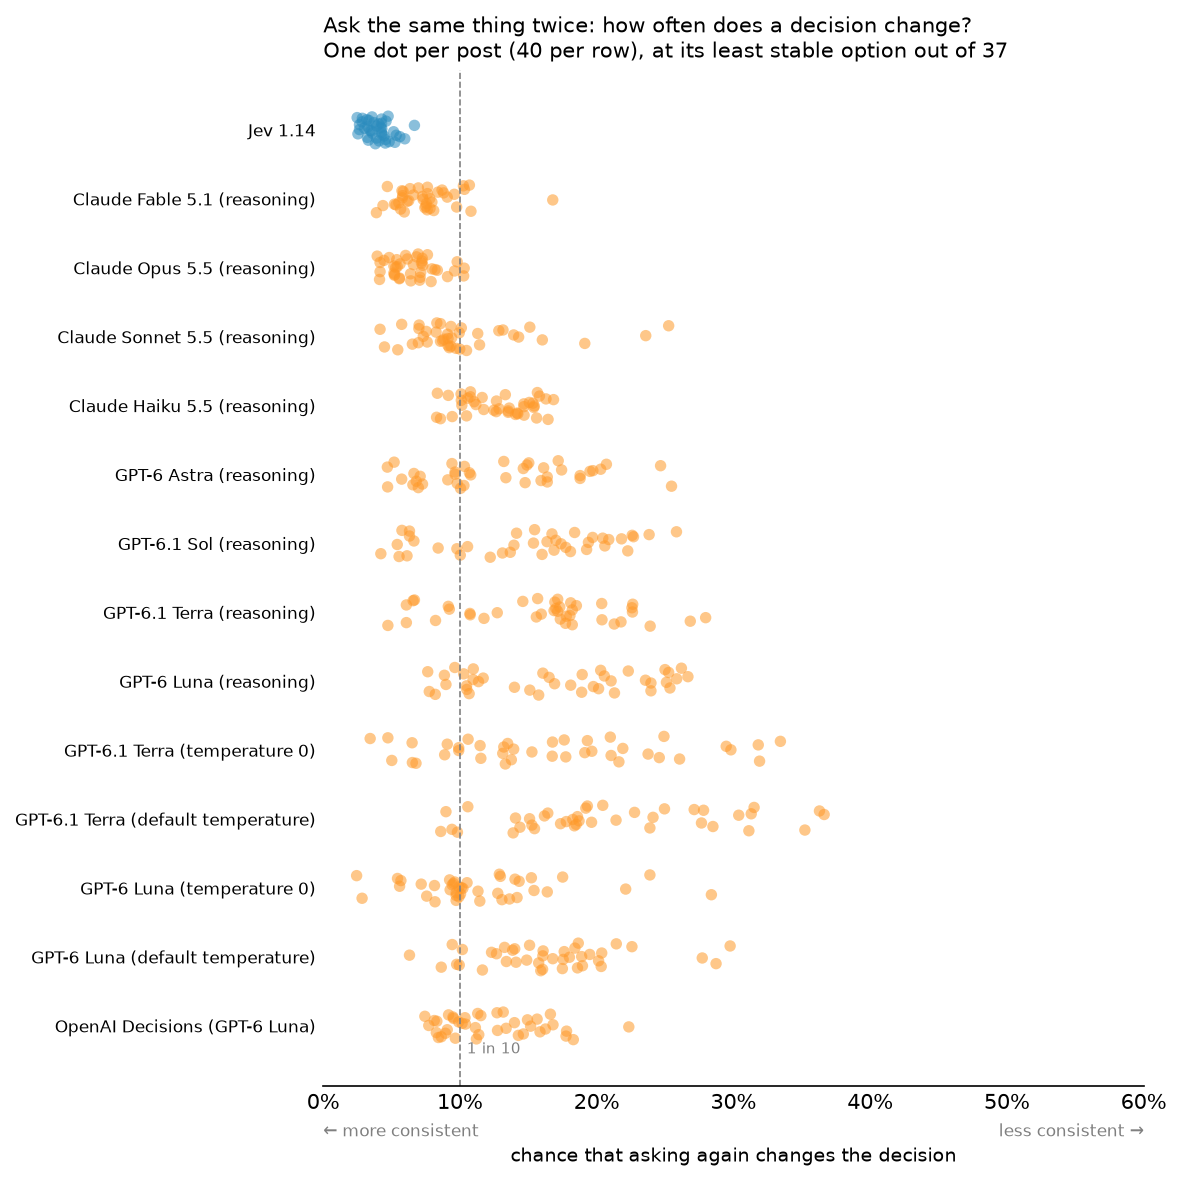

In [ ]:
STRIP_PALETTES = {
    "light": {"surface": "#ffffff", "ink": "#000000", "muted": "#808080", "jev": "#2b8cbe", "llm": "#fe9929", "alpha": 0.55},
    "dark": {"surface": "#0d0a0f", "ink": "#fafafa", "muted": "#a1a1aa", "jev": "#5fb0e0", "llm": "#fe9929", "alpha": 0.7},
}


def draw_strip(p: dict) -> plt.Figure:
    fig_strip, strip_ax = plt.subplots(figsize=(8, 0.5 * len(STRIP_ORDER) + 1), facecolor=p["surface"])
    strip_ax.set_facecolor(p["surface"])
    for position, label in enumerate(STRIP_ORDER):
        values = least_stable[label]
        # spread the posts vertically so dots with close values stay countable
        strip_ax.scatter(
            values,
            position + np.linspace(-0.2, 0.2, len(values)),
            s=30,
            alpha=p["alpha"],
            color=p["jev"] if label == TYPESAFE_LABEL else p["llm"],
            edgecolors="none",
        )
    strip_ax.axvline(0.10, color=p["muted"], linewidth=0.8, linestyle="--")
    strip_ax.text(0.105, len(STRIP_ORDER) - 0.55, "1 in 10", fontsize=7, color=p["muted"], va="bottom")
    strip_ax.set_yticks(range(len(STRIP_ORDER)), STRIP_ORDER, fontsize=8)
    strip_ax.invert_yaxis()  # first row on top
    strip_ax.set_xlim(0, 0.6)
    strip_ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    strip_ax.set_xlabel("chance that asking again changes the decision", fontsize=9, labelpad=16)
    for x, text, align in ((0, "← more consistent", "left"), (1, "less consistent →", "right")):
        # a fixed offset below the axis, so the labels sit above the x label at any height
        strip_ax.annotate(text, (x, 0), xycoords="axes fraction", xytext=(0, -18),
                          textcoords="offset points", ha=align, va="top", fontsize=8,
                          color=p["muted"])
    for edge in ("top", "right", "left"):
        strip_ax.spines[edge].set_visible(False)
    strip_ax.tick_params(length=0, labelcolor=p["ink"])
    strip_ax.spines["bottom"].set_color(p["ink"])
    strip_ax.xaxis.label.set_color(p["ink"])
    strip_ax.set_title(
        "Ask the same thing twice: how often does a decision change?\n"
        f"One dot per post ({NUM_POSTS} per row), at its least stable option out of "
        f"{sum(len(choices) for _instructions, choices in QUESTIONS.values())}",
        loc="left",
        fontsize=10,
        color=p["ink"],
    )
    fig_strip.tight_layout()
    return fig_strip


# The docs build sets COOKSAFE_RENDER and also draws a dark copy.
for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
    fig_strip = draw_strip(STRIP_PALETTES[theme])
    display(fig_strip, metadata={"theme": theme})
    plt.close(fig_strip)

## Open it in the TypeSafe playground

The link below opens the example post and rubric in the playground: one post, the same 8
`Choice` questions, and `jev-latest`.

In [ ]:
playground_link = make_playground_link(
    {"post": POST},
    {
        key: Choice(instructions=instructions, criteria=choices)
        for key, (instructions, choices) in QUESTIONS.items()
    },
)
display(
    Markdown(
        f"🔗 [Open this post + rubric in the TypeSafe playground]({playground_link})"
    )
)

🔗 [Open this post + rubric in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIwAOiAA4QDOKpBJ5VKA+gJZi36kAKAtABx8ATAEYAzKQA0nEAEMYKABYQATh3oxKCZa3Z5pGrUwAsRgOzDJ0mVCgQYqJjIDmCJmBkBPSh1F8ppMmUWFSZqIIBrBG89YX8QADMIABskiAB3LWiCEQAGAF8421QsGj16ShhleOsEDgCYACMklih8ZQQyJI9LUhYkJnbOjyYUCDrZJAhFLXwDZXwwBHjkMD6nfBl8JxlEfDIZFCgFHpBbODh7FhRuvVIsHc6EHm3EHkWGg6jSAukilGRSnRSP9sOMAILtfAeOz4TRBOyULr4RQsSgLZCaAD8+DBSGhSAQ+DSSnRyyQYDRigOewOR3wqI2+DOj3+TNSaSQG3JsKUMCSYHwDUJCDgH2UyhklE0AtG+AQADdkHtGPgFFoEAA6fBcBAQR74ZqRKEwmSQ4kHADkaOUMD6a2RCgZZwuSCuHi5AqUBOoSOhMHwBIQMoggsJixkSRQRKuCi1AGEILtKJ56VHZXB3dUoAgpH15VcEFa2iwnAoo2r2lqANIIDqp2ZkD34ACSFpScu5fvmxOShKOMiQBKSGpOCklTGaSHCHBQNpz0kn4TciZkfXG-ZQGvucEeJySA6cMGctVuIGQ3zigxUKCy+HUcIGHWvt6Ml6fymY7UlECQt4A2qQY4SlKiCoCclD7HAJyKF+pQALp5IhIBSOQyiJmQN4YNgehEKQUCfE4Kg3ECIDXGQJ4EHhSgtCecR9GEMBQCgwS-uMADqY5Rgy0ywmsSSEnAKoyGQnQtDITR9j+-yoDwFDNFA7r4f8hHKJmKgOgyFDUJiJxQEE-xBDIaikAAcj+FHSGZyrye6+bJAcLH4BA8Rcu64R9GAI7IdIAASpqSrepDNr+fI3k58yLIgA5ops5HKJQP5SGkMYBiGMEINSzmqqacBNpMexof8TFBjwUD7lKGwoCg1jhF5cR+f84JVTVMV7JkP7hVsaEwI2ECKvMsWFQgxUCv2ErFUE1AtPgAAU43zu0zROCxUguOSWhSBqW0AJR1dIABqwT8Ug2bjAAsjIkStXpQYsBJDqwU5LlAbl6l9FABZonZx3Zhs2z0VGCWIOZe2kAAypB4wAKq-skLQFgKgSJlMjnqYusKQUlKX5XFCVIBGlXVVAtUnGDWBHkk4xk5gFOdTIYChUyUkAl5iFxIELBwKawyTdOZTAh45HrtRp3eb0v6zoxzE-oFIAcdS3FqgVnPc-ggmLBK0ucrzDrUpQvL8gsQSKsihkuPgiTzCiaJaSgOli6c+laCwRn8yAfnAZQoGAtIOrxT+BMHET4SddVyguP8AriQY9KUkrXN9MWlAkw7h29idFmkGCD0ZVGWUvZ1fTMXAbAOR1isCau2uoincQADJ9OEYINAY4wAKLYFo+NJDw6Pqc58SyfuKCW7ltgqKs+Na0nIcV2rVcz6DIBgjYdioD5qKjKp4xcPCA2r-Y5ab0RnWDLnoZjnZ8xzwn1fJ0vdfpAASjX4xWVFrpIE48R8mrEAa2XO+s8bbtE0KgVmPxgSmgjsZUigtM6nBFrRaQAMbRMRYrLDiIZ1Lmi4nHSSxRUDKy5kEJEqx2gjUqvbQoTtDKwLMgSN+UwFgsAoZHSqrlzL0k5PsD8LQ+SmiXn7PG4wAAirDhrsMygSDGw0WDxGmh5Fg+YGYRiXgAcW6mQMREjKHUkGlMSRQYup2F6vMMqAUhHD1HjothxjqQ8WdJca4nVOgHFHqmTQSR4hSEmFGWK7UkAQLiNYLWsCyIIKOBAGiJxUFSwwexTiHZLbZm9hsdBHV9Z2ENkKZEl0lQdWtsqbSulaEu1gWCFI6Rxh1wyibHitsGzRkUKldJWsl5sVNEgGpdTCQNJVD1QU8hCbWAUIyNIXT7T7iFMOE4T8RR9QQfMwS9Sla2ykC3KMkBUpRnIt3FgAAvPpStrC2EPkvMGs4WCRHGMsxZDpCSNIHFHMAUdYRXKNLKHipy16bhOG3Sg+Fh4ILQPk1pchRhcykRkpAABuVUyQBSW0ZAoeAA50QfUoCxYJ0gACOMAEAEvCfA4W0TRZ0QlmgrWmDHR0ixV-fif8AHT3xYSwkWS+QCnSJyIpttqG-DKa7EiYJ5BjFPCK0YPBQHJEVPC-KqKuaclZQSgMtZFieROOo5AWgIzjC1QSCUSQmU6pZQSglS80AKFguMS1j0AD0+BvrIF+qAigv5CTKs1KTSGp4IY7CbG4keKg4A8GjpofAnqLVg1qfTG1NpqChvJDwZMywXH8XpvgB1YDgjzEjd8SBIBFxMDHOSScThiVC1PFEmJDs4kwtlj5dIPJslRzxHKTuyhu4Gkbp1AeQ93HBu4fmVkid+nUFDNlUtQZ+V4UFRUqpaQekyFWYSdGic3HZiXk-OADcpxUyuWYlhyZ7o8XRps-AkQ6xjr+Q7AAQkEbYiw43n1PT2yUTMJ59E+AKBoD76b2meW0xyVwNgxRbpoJeAKgWfCpisB53apzIhDJsCCciIybyQ6BzQFUhSW0JKEtYOLSDtHzAgNITB9iKArZEpBsTKXxJlokkMHLDZc0+UrBRXagVGsKY6G2jAZ2OwLHQt2EqxWUWXqKqF9iYVypDAq9FJGWBkaXj5NF3TxUWzQqgSchIFOcnVia9SbGojwe4xc5AObwSwks-3eYqGProfHUpsjMwGTtHxRIjVDtanbEpqeJ+dhWSyn4n5zq+40g8GQCkkUAI5SAojIAojIBND9TdNR0lNaKUMXrYkhW+CnL9QjEa1LzsXFZV5QJ0pwnyluwYQgqy30ksnEfougLMBFidVWF7VEWLFQbOGVEMBzFivuhevxKUS8zq3XgDvQJBMgIBTSclFp+UyoZWUEiG6qwT1WtzqpksxxTweyW3F0YEcKzNLGZsdKDiklnJyYSL8Uc0TbbuvxCBeRvKyDICwfamQWI4XlMIEAeQgA)